# E3 — Class-weighted TF-IDF + Linear SVM — Hindi and Bengali

**Project:** Indic Climate Stance Detection  
**Languages:** Hindi and Bengali (trained and evaluated independently)  
**Labels:** 0 = Against, 1 = Favour, 2 = None

**Purpose:** Class-weighted Linear SVM. Scikit-learn computes inverse-frequency class weights from the training labels only.

This is a compact experiment notebook. It automatically asks you to upload the Stage 1 dataset ZIP, extracts it, runs both languages, and exports only the small results required for observation and analysis.

## 1. Install packages

In [1]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn

## 2. Imports and fixed experiment settings

In [2]:
import zipfile, os, json, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

SEED = 42
LABEL_IDS = [0, 1, 2]
LABEL_NAMES = ["Against", "Favour", "None"]

EXPERIMENT = "E3_Class_Weighted_TFIDF_Linear_SVM"
OUTPUT_FOLDER = "E3_small_results"
CLASS_WEIGHT = 'balanced'
print("Experiment:", EXPERIMENT)
print("class_weight:", CLASS_WEIGHT)
print("TF-IDF: word unigrams + bigrams; max_features=50000")
print("SVM: LinearSVC(C=1.0)")

Experiment: E3_Class_Weighted_TFIDF_Linear_SVM
class_weight: balanced
TF-IDF: word unigrams + bigrams; max_features=50000
SVM: LinearSVC(C=1.0)


## 3. Upload and automatically extract the dataset ZIP
Upload your `indic_climate_stage1_cleaned.zip`. The notebook expects the six CSV files included in your uploaded archive: `hindi_train.csv`, `hindi_val.csv`, `hindi_test.csv`, and the equivalent Bengali files.

In [3]:
# Upload the dataset ZIP once. The notebook automatically extracts it.
from google.colab import files

uploaded = files.upload()
zip_files = [name for name in uploaded.keys() if name.lower().endswith(".zip")]
if not zip_files:
    raise ValueError("Please upload indic_climate_stage1_cleaned.zip")

ZIP_PATH = zip_files[0]
DATA_DIR = Path("/content/indic_climate_stage1_cleaned")
DATA_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DATA_DIR)

print("Dataset extracted. Required files:")
for language in ["hindi", "bengali"]:
    for split in ["train", "val", "test"]:
        f = DATA_DIR / f"{language}_{split}.csv"
        print(f"{f.name}: {'FOUND' if f.exists() else 'MISSING'}")


Saving indic_climate_stage1_cleaned.zip to indic_climate_stage1_cleaned.zip
Dataset extracted. Required files:
hindi_train.csv: FOUND
hindi_val.csv: FOUND
hindi_test.csv: FOUND
bengali_train.csv: FOUND
bengali_val.csv: FOUND
bengali_test.csv: FOUND


## 4. Load and validate the splits

In [4]:
def load_split(language, split):
    path = DATA_DIR / f"{language}_{split}.csv"
    df = pd.read_csv(path)

    required = {"example_id", "original_text", "text", "label"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path.name} missing columns: {missing}")

    df = df.dropna(subset=["text", "label"]).copy()
    df["text"] = df["text"].astype(str).str.strip()
    df["label"] = df["label"].astype(int)
    df = df[df["text"].ne("")].reset_index(drop=True)

    if not set(df["label"].unique()).issubset(set(LABEL_IDS)):
        raise ValueError("Expected labels: 0=Against, 1=Favour, 2=None")
    return df

def class_distribution(train_df, val_df, test_df):
    rows = []
    for split_name, df in [
        ("train", train_df), ("validation", val_df), ("test", test_df)
    ]:
        counts = df["label"].value_counts().reindex(LABEL_IDS, fill_value=0)
        for label_id, label_name, count in zip(LABEL_IDS, LABEL_NAMES, counts):
            rows.append({
                "split": split_name,
                "class": label_name,
                "count": int(count),
                "percentage": round(100 * count / len(df), 2)
            })
    return pd.DataFrame(rows)


## 5. Train and evaluate both languages
The notebook fits the TF-IDF vocabulary on training data only. It reports validation metrics, test metrics, per-class test scores and confusion matrices. The test set is used only for final evaluation.


LANGUAGE: HINDI
Split sizes: 2871 354 355
Validation — Accuracy: 0.8249 | Macro-F1: 0.4498
Test       — Accuracy: 0.7972 | Macro-F1: 0.4339 | Weighted-F1: 0.7525

Test classification report:
              precision    recall  f1-score   support

     Against     0.2000    0.0571    0.0889        35
      Favour     0.8248    0.9579    0.8864       285
        None     0.5714    0.2286    0.3265        35

    accuracy                         0.7972       355
   macro avg     0.5321    0.4145    0.4339       355
weighted avg     0.7382    0.7972    0.7525       355



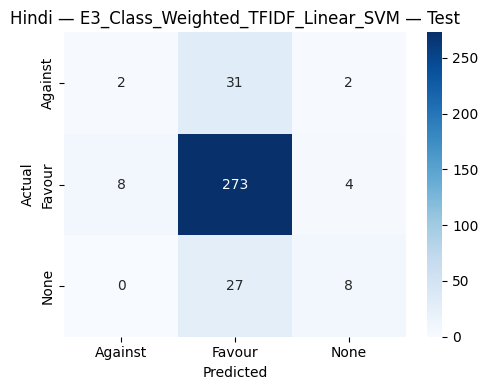


LANGUAGE: BENGALI
Split sizes: 2871 354 355
Validation — Accuracy: 0.8023 | Macro-F1: 0.4375
Test       — Accuracy: 0.7915 | Macro-F1: 0.3855 | Weighted-F1: 0.7377

Test classification report:
              precision    recall  f1-score   support

     Against     0.2000    0.0571    0.0889        35
      Favour     0.8185    0.9649    0.8857       285
        None     0.4444    0.1143    0.1818        35

    accuracy                         0.7915       355
   macro avg     0.4876    0.3788    0.3855       355
weighted avg     0.7206    0.7915    0.7377       355



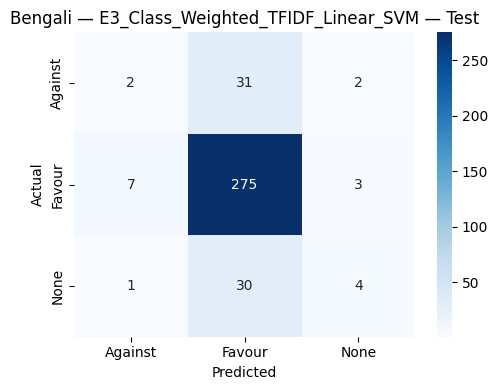


===== COMBINED METRICS: HINDI + BENGALI =====


,experiment,language,validation_accuracy,validation_macro_f1,test_accuracy,test_macro_f1,test_weighted_f1
0,E3_Class_Weighted_TFIDF_Linear_SVM,hindi,0.8249,0.4498,0.7972,0.4339,0.7525
1,E3_Class_Weighted_TFIDF_Linear_SVM,bengali,0.8023,0.4375,0.7915,0.3855,0.7377



===== TEST CLASS-WISE METRICS =====


,experiment,language,class,precision,recall,f1,support
0,E3_Class_Weighted_TFIDF_Linear_SVM,hindi,Against,0.2000,0.0571,0.0889,35
1,E3_Class_Weighted_TFIDF_Linear_SVM,hindi,Favour,0.8248,0.9579,0.8864,285
2,E3_Class_Weighted_TFIDF_Linear_SVM,hindi,None,0.5714,0.2286,0.3265,35
3,E3_Class_Weighted_TFIDF_Linear_SVM,bengali,Against,0.2000,0.0571,0.0889,35
4,E3_Class_Weighted_TFIDF_Linear_SVM,bengali,Favour,0.8185,0.9649,0.8857,285
5,E3_Class_Weighted_TFIDF_Linear_SVM,bengali,None,0.4444,0.1143,0.1818,35



Only these files are needed for your observation/analysis:
- metrics_summary.csv
- test_classification_report.csv
- hindi_test_confusion_matrix.csv
- bengali_test_confusion_matrix.csv
- hindi_class_distribution.csv
- bengali_class_distribution.csv


In [5]:
# One independent run for Hindi and one for Bengali.
OUTPUT_DIR = Path("/content") / OUTPUT_FOLDER
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

summary_rows = []
class_report_rows = []
confusion_matrices = []

for language in ["hindi", "bengali"]:
    print("\n" + "=" * 65)
    print("LANGUAGE:", language.upper())
    print("=" * 65)

    train_df = load_split(language, "train")
    val_df = load_split(language, "val")
    test_df = load_split(language, "test")

    print("Split sizes:", len(train_df), len(val_df), len(test_df))

    # Fit TF-IDF only on training text; transform validation and test.
    vectorizer = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        max_features=50000,
        sublinear_tf=True,
        min_df=1,
        max_df=0.95
    )
    X_train = vectorizer.fit_transform(train_df["text"])
    X_val = vectorizer.transform(val_df["text"])
    X_test = vectorizer.transform(test_df["text"])

    model = LinearSVC(
        C=1.0,
        class_weight=CLASS_WEIGHT,
        random_state=SEED,
        max_iter=10000
    )
    model.fit(X_train, train_df["label"])

    # Validation metrics
    val_pred = model.predict(X_val)
    val_accuracy = accuracy_score(val_df["label"], val_pred)
    val_macro_f1 = f1_score(
        val_df["label"], val_pred, labels=LABEL_IDS,
        average="macro", zero_division=0
    )

    # Test metrics
    test_pred = model.predict(X_test)
    test_accuracy = accuracy_score(test_df["label"], test_pred)
    test_macro_f1 = f1_score(
        test_df["label"], test_pred, labels=LABEL_IDS,
        average="macro", zero_division=0
    )
    test_weighted_f1 = f1_score(
        test_df["label"], test_pred, labels=LABEL_IDS,
        average="weighted", zero_division=0
    )

    print(f"Validation — Accuracy: {val_accuracy:.4f} | Macro-F1: {val_macro_f1:.4f}")
    print(f"Test       — Accuracy: {test_accuracy:.4f} | Macro-F1: {test_macro_f1:.4f} | Weighted-F1: {test_weighted_f1:.4f}")

    summary_rows.append({
        "experiment": EXPERIMENT,
        "language": language,
        "validation_accuracy": val_accuracy,
        "validation_macro_f1": val_macro_f1,
        "test_accuracy": test_accuracy,
        "test_macro_f1": test_macro_f1,
        "test_weighted_f1": test_weighted_f1
    })

    # Per-class metrics (test set)
    report = classification_report(
        test_df["label"], test_pred,
        labels=LABEL_IDS, target_names=LABEL_NAMES,
        output_dict=True, zero_division=0
    )
    for class_name in LABEL_NAMES:
        class_report_rows.append({
            "experiment": EXPERIMENT,
            "language": language,
            "class": class_name,
            "precision": report[class_name]["precision"],
            "recall": report[class_name]["recall"],
            "f1": report[class_name]["f1-score"],
            "support": int(report[class_name]["support"])
        })

    # Confusion matrix (test set)
    cm = confusion_matrix(test_df["label"], test_pred, labels=LABEL_IDS)
    cm_df = pd.DataFrame(cm, index=LABEL_NAMES, columns=LABEL_NAMES)
    cm_df.index.name = "actual"
    cm_df.to_csv(OUTPUT_DIR / f"{language}_test_confusion_matrix.csv")
    confusion_matrices.append((language, cm))

    print("\nTest classification report:")
    print(classification_report(
        test_df["label"], test_pred,
        labels=LABEL_IDS, target_names=LABEL_NAMES,
        digits=4, zero_division=0
    ))

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
    plt.title(f"{language.title()} — {EXPERIMENT} — Test")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    # Save only compact, useful artifacts.
    class_distribution(train_df, val_df, test_df).to_csv(
        OUTPUT_DIR / f"{language}_class_distribution.csv", index=False
    )

# Save combined summaries for observation and analysis.
summary_df = pd.DataFrame(summary_rows)
class_report_df = pd.DataFrame(class_report_rows)

summary_df.to_csv(OUTPUT_DIR / "metrics_summary.csv", index=False)
class_report_df.to_csv(OUTPUT_DIR / "test_classification_report.csv", index=False)

print("\n===== COMBINED METRICS: HINDI + BENGALI =====")
display(summary_df.round(4))

print("\n===== TEST CLASS-WISE METRICS =====")
display(class_report_df.round(4))

print("\nOnly these files are needed for your observation/analysis:")
print("- metrics_summary.csv")
print("- test_classification_report.csv")
print("- hindi_test_confusion_matrix.csv")
print("- bengali_test_confusion_matrix.csv")
print("- hindi_class_distribution.csv")
print("- bengali_class_distribution.csv")


## 6. Download compact analysis results
The ZIP contains only metrics, per-class scores, confusion matrices, and class distributions for both languages. It does not include large model/vectorizer files or per-example prediction dumps.

In [6]:
# Download one compact ZIP containing only analysis-ready results.
from google.colab import files

zip_path = shutil.make_archive(
    str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR
)
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Files to use in your research observation

1. `metrics_summary.csv` — validation and test Accuracy, Macro-F1, Weighted-F1 for Hindi and Bengali.
2. `test_classification_report.csv` — precision, recall, F1 and support for Against, Favour and None.
3. `hindi_test_confusion_matrix.csv` and `bengali_test_confusion_matrix.csv` — class-level error patterns.
4. `hindi_class_distribution.csv` and `bengali_class_distribution.csv` — split-wise class counts.

**Primary comparison metric:** Test Macro-F1, because the dataset is class-imbalanced. Do not compare accuracy alone.